# **BERT 실습**

사전학습된 한국어 BERT를 불러와서 BERT가 문맥을 어떻게 이해하는지 직접 확인해보자.

사용 모델: `klue/bert-base`


**1. 필요한 라이브러리 설치**


In [2]:
!pip -q install transformers

In [1]:
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel, AutoModelForMaskedLM

**2. 사전학습된 한국어 BERT 불러오기**

직접 모델을 구현, 학습시키지 않고 HuggingFace에 공개된 `klue/bert-base`를 사용한다.


In [3]:
model_name = "klue/bert-base"

tokenizer = AutoTokenizer.from_pretrained(model_name)
mlm_model = AutoModelForMaskedLM.from_pretrained(model_name)

bert_model = AutoModel.from_pretrained(
    model_name,
    output_attentions=True
)

config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/289 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/248k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/495k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  445MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: klue/bert-base
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: klue/bert-base
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## **실습 1. [MASK]에 들어갈 단어 맞히기**

BERT는 문장의 앞뒤 문맥을 보고 `[MASK]` 위치에 들어갈 단어를 예측할 수 있다.


In [7]:
sentence = "나는 오늘 학교에서 [MASK]을 먹었다."

inputs = tokenizer(
    sentence,
    return_tensors="pt"
)

with torch.no_grad():
    outputs = mlm_model(**inputs)

mask_index = (inputs["input_ids"][0] == tokenizer.mask_token_id).nonzero(as_tuple=True)[0]
logits = outputs.logits[0, mask_index]
top5 = torch.topk(logits,k=5,dim=1)

print("문장 :", sentence)

문장 : 나는 오늘 학교에서 [MASK]을 먹었다.


In [8]:
for token_id in top5.indices[0]:
    print(tokenizer.decode([token_id]))


점심
치킨
저녁
짜장면
아이스크림


**문장을 바꿔서 결과를 비교해보자.**

- 나는 오늘 학교에서 [MASK]을 먹었다.
- 나는 오늘 학교에서 [MASK]을 공부했다.
- 나는 주말에 친구와 [MASK]을 보았다.


## **실습 2. 문장 유사도 비교**

BERT가 만든 문장 표현을 이용해 문장끼리 얼마나 비슷한지 비교해본다.

여기서는 각 Token의 BERT 출력을 평균내어 하나의 문장 Vector로 사용한다.

※ `klue/bert-base`는 문장 유사도 전용 모델이 아니다.
- 여기서는 BERT Embedding의 개념을 확인하는 간단한 실습으로 사용한다.



In [9]:
sentences = [
    "오늘 날씨가 정말 춥다.",
    "밖에 나가니 너무 추웠다.",
    "나는 피자를 좋아한다.",
    "겨울에는 기온이 많이 내려간다."
]

inputs = tokenizer(
    sentences,
    padding=True,
    truncation=True,
    return_tensors="pt"
)

with torch.no_grad():
    outputs = bert_model(
        **inputs,
        output_attentions=False
    )

token_embeddings = outputs.last_hidden_state
mask = inputs["attention_mask"].unsqueeze(-1)

sentence_embeddings = (
    (token_embeddings * mask).sum(dim=1)
    / mask.sum(dim=1)
)

similarities = torch.nn.functional.cosine_similarity(
    sentence_embeddings[0].unsqueeze(0),
    sentence_embeddings,
    dim=1
)

print("기준 문장 :", sentences[0])


기준 문장 : 오늘 날씨가 정말 춥다.


In [10]:
for sentence, score in zip(sentences, similarities):
    print(f"{score.item():.3f} | {sentence}")

1.000 | 오늘 날씨가 정말 춥다.
0.763 | 밖에 나가니 너무 추웠다.
0.601 | 나는 피자를 좋아한다.
0.777 | 겨울에는 기온이 많이 내려간다.


## **실습 3. Attention Heatmap**

BERT 내부의 Self-Attention Weight를 꺼내서,

**각 단어가 같은 문장의 다른 단어를 얼마나 참고했는지** Heatmap으로 확인한다.


In [13]:
# 한글 설치
!pip install -q koreanize-matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import koreanize_matplotlib
plt.rcParams['axes.unicode_minus'] = False

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 56.2 MB/s eta 0:00:00


In [14]:
sentence = "철수는 학교에서 친구와 책을 읽었다."

inputs = tokenizer(
    sentence,
    return_tensors="pt"
)

with torch.no_grad():
    outputs = bert_model(
        **inputs,
        output_attentions=True
    )

tokens = tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0]
)

print(tokens)

['[CLS]', '철수', '##는', '학교', '##에서', '친구', '##와', '책', '##을', '읽', '##었', '##다', '.', '[SEP]']


BERT는 여러 Layer와 여러 Attention Head를 사용한다.

여기서는 **마지막 Layer의 첫 번째 Head**만 골라서 확인한다.

색이 진한 칸일수록 해당 단어를 더 많이 참고했다는 뜻이다.

단, Attention Weight 하나만으로 모델의 판단 이유 전체를 설명할 수 있는 것은 아니다.


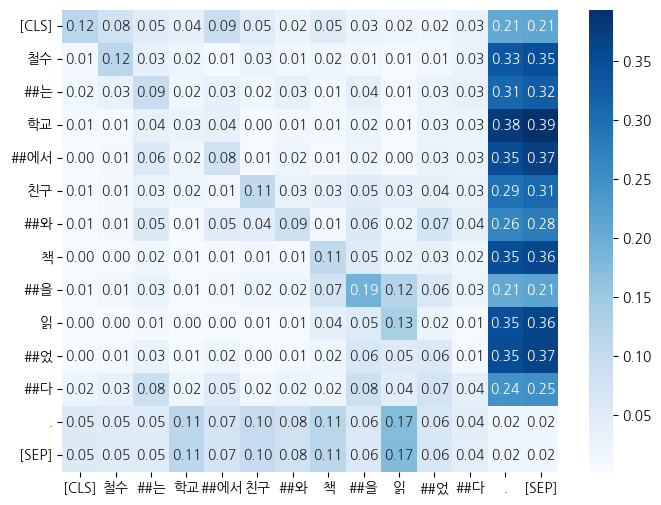

In [34]:
attention = outputs.attentions[-1][0, 0].cpu().numpy()

plt.figure(figsize=(8,6))
sns.heatmap(
    attention,
    cmap="Blues",
    xticklabels=tokens,
    yticklabels=tokens,
    annot=True,
    fmt=".2f"
)
plt.show()